# 04 Feature importance: which household characteristics matter most?

**Goal of this notebook:** find out which household variables the models rely on most, and compare this with the practicum's ANOVA findings (research question RQ5).

- **Method:** *permutation importance* on the **test set**. We shuffle one variable at a time and see how much the score drops. A big drop means the model needs that variable.
- **Scores used:** R² for regression, macro F1 for classification.
- **Models:** the best settings found in notebooks 02 and 03 are read from the results files and refitted on the training set. We check that the test scores match the earlier ones.
- **Settings:** Setting B (all variables) is the main one. Setting A (four variables) is used for the comparison with the practicum.

Run notebooks 02 and 03 first, because this notebook reads `../reports/regression_results.csv` and `../reports/classification_results.csv`.

How to use it: run one cell at a time (Shift+Enter) and read the output. Every section ends with a **Check yourself** question.

## Step 1. Import the tools

In [1]:
import sys
sys.path.append("..")            # lets us import our own code from the src/ folder

import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance   # the importance method
from sklearn.metrics import r2_score, f1_score

from src.data import load_clean, make_split
from src.config import (TARGET, FEATURES_A, FEATURES_B, NUMERIC, CATEGORICAL, SEED, FIG_DIR)

## Step 2. Load the data and use the SAME shared split
Same 80/20 split (seed 42) as notebooks 02 and 03.

In [2]:
df = load_clean()
train, test, cuts = make_split(df)
print("train rows:", len(train), "| test rows:", len(test))

train rows: 4115 | test rows: 1029


## Step 3. Helpers
1. `LABELS` gives each variable a readable name (from Table 1 in the thesis).
2. Two preprocessors, as in the earlier notebooks: for regression, income is passed through unchanged; for classification, income is scaled.
3. `get_best_params` reads the best settings that notebooks 02 and 03 saved in their results files.
4. `refit` builds the model with those settings and fits it on the **training** set.

In [3]:
LABELS = {
    "income": "Income", "maininc": "Main income source", "A172": "Internet connection",
    "A093r": "Economic position", "A094r": "Occupational class", "A121r": "Tenure",
    "SexHRP": "Sex of reference person", "hhsize": "Household size",
    "G018r": "Number of adults", "G019r": "Number of children", "Gorx": "Region",
}


def make_preprocessor(features, scale_income):
    cat_cols = [c for c in features if c in CATEGORICAL]
    num_cols = [c for c in features if c in NUMERIC]
    num_step = StandardScaler() if scale_income else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
        ("num", num_step, num_cols),
    ])


reg_results = pd.read_csv("../reports/regression_results.csv")
clf_results = pd.read_csv("../reports/classification_results.csv")


def get_best_params(results, setting, model_name):
    row = results[(results["Setting"] == setting) & (results["Model"] == model_name)].iloc[0]
    return ast.literal_eval(row["Best settings"])     # turns the text "{...}" back into a dictionary


regression_models = {
    "Linear regression": lambda: LinearRegression(),
    "Random forest": lambda: RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
    "XGBoost": lambda: XGBRegressor(random_state=SEED, n_jobs=-1),
}
classification_models = {
    "Logistic regression": lambda: LogisticRegression(max_iter=2000),
    "Random forest": lambda: RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}


def refit(task, setting, model_name):
    features = FEATURES_A if setting == "A" else FEATURES_B
    if task == "regression":
        model = regression_models[model_name]()
        params = get_best_params(reg_results, setting, model_name)
        y_train = train[TARGET]
        prep = make_preprocessor(features, scale_income=False)
    else:
        model = classification_models[model_name]()
        params = get_best_params(clf_results, setting, model_name)
        y_train = train["segment"]
        prep = make_preprocessor(features, scale_income=True)
    pipe = Pipeline([("prep", prep), ("model", model)]).set_params(**params)
    pipe.fit(train[features], y_train)
    return pipe, features

## Step 4. Refit the models and check the scores
Before measuring importance, we check that the refitted models give the same test scores as in notebooks 02 and 03. If they do, we are explaining the same models.

In [4]:
fitted = {}     # (task, setting, model) -> (pipeline, features)
rows = []

for setting in ["A", "B"]:
    for name in regression_models:
        pipe, feats = refit("regression", setting, name)
        fitted[("regression", setting, name)] = (pipe, feats)
        score = r2_score(test[TARGET], pipe.predict(test[feats]))
        saved = reg_results[(reg_results["Setting"] == setting) & (reg_results["Model"] == name)]["Test R2"].iloc[0]
        rows.append({"Task": "regression", "Setting": setting, "Model": name, "Test score now": score, "Saved score": saved})
    for name in classification_models:
        pipe, feats = refit("classification", setting, name)
        fitted[("classification", setting, name)] = (pipe, feats)
        score = f1_score(test["segment"], pipe.predict(test[feats]), average="macro")
        saved = clf_results[(clf_results["Setting"] == setting) & (clf_results["Model"] == name)]["Test Macro F1"].iloc[0]
        rows.append({"Task": "classification", "Setting": setting, "Model": name, "Test score now": score, "Saved score": saved})

check = pd.DataFrame(rows)
check["Difference"] = (check["Test score now"] - check["Saved score"]).abs()
check.round(3)

,Task,Setting,Model,Test score now,Saved score,Difference
0,regression,A,Linear regression,0.416,0.416,0.0
1,regression,A,Random forest,0.412,0.412,0.0
2,regression,A,XGBoost,0.415,0.415,0.0
3,classification,A,Logistic regression,0.620,0.620,0.0
4,classification,A,Random forest,0.607,0.607,0.0
5,regression,B,Linear regression,0.554,0.554,0.0
6,regression,B,Random forest,0.559,0.559,0.0
7,regression,B,XGBoost,0.568,0.568,0.0
8,classification,B,Logistic regression,0.672,0.672,0.0
9,classification,B,Random forest,0.668,0.668,0.0


**Check yourself:** are the differences close to zero? Why is it important that we explain the *same* models that were evaluated before?

**Answer:** Yes, the differences are close to zero: the refitted models reproduce the saved test scores. This is a useful check that we are evaluating the same model settings and data split as in notebooks 02 and 03, so the feature-importance results can be interpreted alongside those earlier results.

## Step 5. Permutation importance
For each model, every variable is shuffled 20 times on the **test set**. Because the pipeline takes the original columns, shuffling a variable shuffles *all* its 0/1 columns together, so we get one importance per original variable.
The importance is the **average drop in the score** (R² for regression, macro F1 for classification). A drop near zero means the model does not need that variable.

In [5]:
importance_rows = []

for (task, setting, name), (pipe, feats) in fitted.items():
    if task == "regression":
        y_test, scoring = test[TARGET], "r2"
    else:
        y_test, scoring = test["segment"], "f1_macro"

    result = permutation_importance(pipe, test[feats], y_test, scoring=scoring,
                                    n_repeats=20, random_state=SEED, n_jobs=1)
    for i, var in enumerate(feats):
        importance_rows.append({"Task": task, "Setting": setting, "Model": name, "Variable": var,
                                "Label": LABELS[var],
                                "Importance": result.importances_mean[i],
                                "Std": result.importances_std[i]})

importance = pd.DataFrame(importance_rows)
importance.round(4).to_csv("../reports/feature_importance.csv", index=False)
importance.shape

d:\files od DS\Thesis\Work\lcf-expenditure-ml\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\files od DS\Thesis\Work\lcf-expenditure-ml\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\files od DS\Thesis\Work\lcf-expenditure-ml\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\files od DS\Thes

(75, 7)

## Step 6. Regression, Setting B
Importance of each variable for the three regression models (average drop in R²), sorted by the best model, XGBoost.

In [6]:
reg_b = importance[(importance["Task"] == "regression") & (importance["Setting"] == "B")]
table_reg_b = reg_b.pivot(index="Label", columns="Model", values="Importance")
table_reg_b = table_reg_b[["Linear regression", "Random forest", "XGBoost"]].sort_values("XGBoost", ascending=False)
table_reg_b.round(3)

Model,Linear regression,Random forest,XGBoost
Label,,,
Income,0.563,0.689,0.579
Household size,0.062,0.021,0.027
Number of adults,0.008,0.018,0.021
Internet connection,0.016,0.013,0.021
Occupational class,0.033,0.007,0.016
Tenure,0.009,0.003,0.009
Main income source,0.004,0.001,0.003
Region,0.006,0.001,0.003
Economic position,0.003,0.003,0.001


**Check yourself:** (1) Which variable matters most, and by how much does R² fall when it is shuffled? (2) Do the three models agree on the top variables?

**Answer:** Income is the most important variable in all three regression models. When income is shuffled, test R² falls by about 0.56 for linear regression, 0.69 for random forest and 0.58 for XGBoost. The size of the drop differs, but all three models rely strongly on income. The other variables have much smaller effects overall, although the exact ranking varies by model.

## Step 7. Classification, Setting B
The same for the two classifiers (average drop in macro F1), sorted by logistic regression, the best classifier.

In [7]:
clf_b = importance[(importance["Task"] == "classification") & (importance["Setting"] == "B")]
table_clf_b = clf_b.pivot(index="Label", columns="Model", values="Importance")
table_clf_b = table_clf_b[["Logistic regression", "Random forest"]].sort_values("Logistic regression", ascending=False)
table_clf_b.round(3)

Model,Logistic regression,Random forest
Label,,
Income,0.212,0.134
Household size,0.020,0.002
Occupational class,0.013,0.009
Region,0.011,0.005
Number of adults,0.009,0.010
Internet connection,0.008,0.017
Number of children,0.005,0.002
Main income source,0.005,0.001
Tenure,0.004,-0.001


**Check yourself:** is the top variable for classification the same as for regression? Does that make sense, since both predict expenditure?

**Answer:** Yes. Income is also the most important variable for classification. Shuffling it lowers test macro F1 by about 0.21 for logistic regression and 0.13 for random forest. This makes sense because both tasks use household characteristics to predict expenditure: regression predicts an amount, while classification predicts a spending group.

## Step 8. A picture of the results
The best model of each task in Setting B, using the same order as the tables.

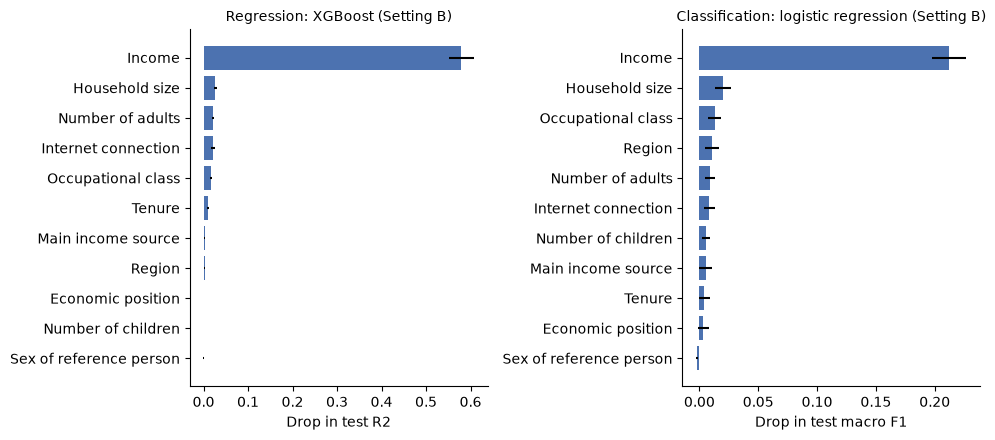

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
panels = [
    (axes[0], reg_b[reg_b["Model"] == "XGBoost"], "Regression: XGBoost (Setting B)", "Drop in test R2"),
    (axes[1], clf_b[clf_b["Model"] == "Logistic regression"], "Classification: logistic regression (Setting B)", "Drop in test macro F1"),
]
for ax, data, title, xlabel in panels:
    data = data.sort_values("Importance")
    ax.barh(data["Label"], data["Importance"], xerr=data["Std"], color="#4C72B0")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.pdf")
plt.savefig(FIG_DIR / "feature_importance.png", dpi=300)
plt.show()

## Step 9. Comparison with the practicum
The practicum used ANOVA with four variables. Its partial effect sizes ranked them (largest first): number of adults, occupational class, tenure, number of children.
Here we rank the same four variables with permutation importance in **Setting A** (linear regression, the closest to the ANOVA), and also look at where they fall in **Setting B**, when income and the other variables are available.

In [9]:
practicum_rank = {"Number of adults": 1, "Occupational class": 2, "Tenure": 3, "Number of children": 4}

# Setting A, linear regression: rank among the four variables
a_lin = importance[(importance["Task"] == "regression") & (importance["Setting"] == "A") &
                   (importance["Model"] == "Linear regression")].copy()
a_lin["Rank in Setting A (linear)"] = a_lin["Importance"].rank(ascending=False).astype(int)

# Setting B, XGBoost: rank among all 11 variables
b_xgb = reg_b[reg_b["Model"] == "XGBoost"].copy()
b_xgb["Rank in Setting B (XGBoost, of 11)"] = b_xgb["Importance"].rank(ascending=False).astype(int)

compare = pd.DataFrame({"Practicum ANOVA rank": pd.Series(practicum_rank)})
compare = compare.join(a_lin.set_index("Label")[["Importance", "Rank in Setting A (linear)"]].rename(columns={"Importance": "Importance (A, linear)"}))
compare = compare.join(b_xgb.set_index("Label")[["Importance", "Rank in Setting B (XGBoost, of 11)"]].rename(columns={"Importance": "Importance (B, XGBoost)"}))
compare.sort_values("Practicum ANOVA rank").round(3)

,Practicum ANOVA rank,"Importance (A, linear)",Rank in Setting A (linear),"Importance (B, XGBoost)","Rank in Setting B (XGBoost, of 11)"
Number of adults,1,0.296,1,0.021,3
Occupational class,2,0.212,2,0.016,5
Tenure,3,0.055,3,0.009,6
Number of children,4,0.027,4,0.000,10


**Check yourself:** (1) Does the ranking of the four variables in Setting A match the practicum's? (2) What happens to the importance of these four variables in Setting B? Which variable takes the top place?

**Answer:** Yes. In Setting A, the linear-regression permutation-importance ranking matches the practicum's ANOVA ranking: number of adults, occupational class, tenure, then number of children. In Setting B, the XGBoost ranking changes: these variables rank 4th, 5th, 6th and 10th out of 11, respectively. Income takes the top position when the additional predictors are included.

## Step 10. A warning about shared information
Some variables carry overlapping information: household size is the number of adults plus children, and economic position and occupational class are related. When variables overlap, the model can use either one, so the importance of each may look **smaller** than it really is, and the split between them is not exact.
Importance also shows what the *model uses to predict*. It does not show what *causes* spending.

**Check yourself:** why should we not say "income causes higher spending" from these results?

**Answer:** We should not say that income causes higher spending because permutation importance shows how much a model relies on income to make predictions; it does not prove cause and effect. Other factors may affect both income and spending, and the data are observational. Related variables, such as household size, number of adults and number of children, also contain overlapping information.

## Step 11. Summary (write this yourself)
Write 4 to 6 sentences in your own words:
1. Which variables matter most for regression in Setting B?
2. Is it the same for classification?
3. Do the models agree with each other?
4. How does this compare with the practicum's ranking of the four variables?
5. What is the main limitation of these importance values?



**Step 11 summary:**

Income is the most important variable for regression in Setting B: shuffling it lowers test R² by about 0.56 for linear regression, 0.69 for random forest and 0.58 for XGBoost. It is also the most important variable for classification, lowering macro F1 by about 0.21 for logistic regression and 0.13 for random forest. The models agree that the other variables are much less important overall, although their exact rankings differ; household size, internet connection, number of adults and occupational class have smaller contributions, while some variables are close to zero. In Setting A, the linear-regression ranking matches the practicum's ANOVA ranking: number of adults, occupational class, tenure and number of children. In Setting B, the XGBoost ranking places these four variables 4th, 5th, 6th and 10th out of 11, while income ranks first. These importance values show which variables the models use for prediction, not what causes household spending; related variables can also share overlapping information.